# 07_02 — Correlations per segment of the stitched acquisition

Uses **only the stitched clean data** produced by `07_01` (`results/data_labelling/stitched_index.csv`: one row per
shot with run, chunk, file and **segment**). A segment is a contiguous stretch of shots: a new segment starts at
every new run and wherever chunks were removed by `CLEAN_CUTS.toml`.

Per shot, the same quantities as notebook 05:

| group | quantities |
|---|---|
| charge | `BCM_GUN` |
| laser | `laser_amp` (matched filter on `laser_scope`, template = mean pulse of the segment), `lab_laser_power` |
| pickups / klystron | `PGLA_drop`, flat-top mean of `PKI15A`, `PKI15P`, `PKR15A` |
| magnets | `DHG0130`, `SNH_110`, `SNI_120` |
| screen | `BTV_amplitude`, `BTV_intensity`, `BTV_mean_x/y`, `BTV_sigma_x/y` (cached per run by `05_correlations_runs`) |
| screen, PCA | `PC1` … `PC6` image scores — preprocessing as notebook 04_1, **one PCA fitted on all stitched shots** so a PC means the same in every segment |

As in 05: group B (laser, pickups, klystron) is shifted one row later **within the segment**, frozen laser-scope /
camera shots are dropped, and the shot-to-shot matrix removes slow drift with a 51-shot rolling mean per segment.

For every segment: one figure, **overall** r (left) and **shot-to-shot** r (right). Saved to
`results/data_labelling/segment_correlations/`. Run `07_01` first.

In [1]:
import os
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from joblib import Parallel, delayed
from scipy import ndimage
from sklearn.utils.extmath import randomized_svd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
STITCHED = REPO / "results" / "data_labelling" / "stitched_index.csv"   # written by 07_01
BTV_CACHE = REPO / "results" / "05_correlations"                        # <run>/btv0125_params.csv from 05_correlations_runs
OUT = REPO / "results" / "data_labelling" / "segment_correlations"
OUT.mkdir(parents=True, exist_ok=True)
N_JOBS = min(32, os.cpu_count() or 1)

FLAT_TOP = slice(300, 640)
GROUP_B = ["laser_amp", "lab_laser_power", "PGLA_drop", "PKI15A", "PKI15P", "PKR15A"]
GROUP_EDGES = ["laser_amp", "PGLA_drop", "DHG0130", "BTV_amplitude", "PC1"]   # first column of each group after charge
BTV_COLS = ["amplitude", "intensity", "mean_x", "mean_y", "sigma_x", "sigma_y"]
DETREND_K = 51

# diverging blue <-> red with a neutral grey midpoint (r = 0), same as notebook 05
DIVERGING = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#cde2fb", "#f0efec", "#f6c6c5", "#e34948", "#9b1c1c"])
INK, MUTED = "#2b2b29", "#8a8985"

idx = pd.read_csv(STITCHED, index_col="shot")
segments = (idx.groupby("segment")
               .agg(run=("run", "first"), first_chunk=("chunk", "min"), last_chunk=("chunk", "max"), shots=("run", "size")))
print(f"{len(idx)} stitched shots, {len(segments)} segments")
segments

63327 stitched shots, 8 segments


,run,first_chunk,last_chunk,shots
segment,,,,
0,acquisition_2026-10-07_21-43-26,11,71,6027
1,acquisition_2026-10-08_00-08-19,0,193,19400
2,acquisition_2026-10-08_15-42-27,0,1,200
3,acquisition_2026-10-08_15-42-27,4,74,7100
4,acquisition_2026-10-08_15-42-27,76,120,4500
5,acquisition_2026-10-08_21-11-47,0,199,20000
6,acquisition_2026-10-09_07-46-07,0,40,4100
7,acquisition_2026-10-09_07-46-07,87,106,2000


## Per-shot table — one parallel pass over the stitched chunks

In [2]:
def chunk_features(fp):
    """Worker, one chunk: scalar features, baseline-subtracted laser pulse, frozen-laser flags, first/last raw pulse."""
    with h5py.File(fp, "r") as f:
        sig = f["laser_scope/signal"][()]
        t = f["laser_scope/times"][0]
        pgla = f["PGLA/samples"][:, 0]
        feats = {
            "BCM_GUN": f["BCM_GUN"][()],
            "lab_laser_power": f["lab_laser_power"][()],
            "PGLA_drop": pgla[:, 631] - pgla[:, 636],
            "PKI15A": f["PKI15A/samples"][:, 0, FLAT_TOP].mean(axis=1),
            "PKI15P": f["PKI15P"][:, 0, FLAT_TOP].mean(axis=1),
            "PKR15A": f["PKR15A"][:, 0, FLAT_TOP].mean(axis=1),
            "DHG0130": f["DHG0130"][()],
            "SNH_110": f["SNH_110"][()],
            "SNI_120": f["SNI_120"][()],
        }
    laser = (sig - sig[:, t < 5].mean(axis=1, keepdims=True)).astype(np.float32)
    frozen = np.r_[False, (sig[1:] == sig[:-1]).all(axis=1)]
    return feats, laser, frozen, sig[:1], sig[-1:], t


files = list(dict.fromkeys(idx["file"]))          # chunk files in stitched order
res = Parallel(n_jobs=N_JOBS, verbose=2)(delayed(chunk_features)(fp) for fp in files)

feats = pd.DataFrame({k: np.concatenate([r[0][k] for r in res]) for k in res[0][0]}, index=idx.index)
laser = np.concatenate([r[1] for r in res])
laser_frozen = np.concatenate([r[2] for r in res])
t = res[0][5]
assert len(feats) == len(idx) and np.allclose(feats["BCM_GUN"], idx["BCM_GUN"], equal_nan=True), "stitched index out of date: re-run 07_01"

# frozen check across chunk boundaries (only inside a segment)
starts = np.r_[0, np.cumsum([len(r[2]) for r in res])[:-1]]
seg = idx["segment"].to_numpy()
for i in range(1, len(res)):
    s = starts[i]
    if seg[s] == seg[s - 1]:
        laser_frozen[s] = (res[i][3] == res[i - 1][4]).all()
del res

# laser matched filter, template = mean pulse of the segment
window = (t > 5.6) & (t < 39.8)
laser_amp = np.empty(len(idx))
for k in segments.index:
    m = seg == k
    template = laser[m].mean(axis=0) * window
    laser_amp[m] = laser[m] @ template / (template @ template)
feats.insert(1, "laser_amp", laser_amp)
del laser
print(feats.shape)

[Parallel(n_jobs=32)]: Using backend LokyBackend with 32 concurrent workers.


[Parallel(n_jobs=32)]: Done 132 tasks      | elapsed:    0.9s


[Parallel(n_jobs=32)]: Done 538 tasks      | elapsed:    1.9s
[Parallel(n_jobs=32)]: Done 571 out of 634 | elapsed:    2.0s remaining:    0.2s
[Parallel(n_jobs=32)]: Done 634 out of 634 | elapsed:    2.1s finished


(63327, 10)


## Camera parameters from the per-run cache of `05_correlations_runs`

In [3]:
parts = []
for run in segments["run"].unique():
    p = BTV_CACHE / run / "btv0125_params.csv"
    if not p.exists():
        print(f"no camera cache for {run}: BTV columns are NaN there (run 05_correlations_runs to create it)")
        continue
    b = pd.read_csv(p, index_col="shot")
    b["chunk"] = b["chunk"].str[6:].astype(int)
    b["shot_in_chunk"] = b.groupby("chunk").cumcount()
    b["run"] = run
    parts.append(b)
btv = pd.concat(parts)[["run", "chunk", "shot_in_chunk", "frozen", *BTV_COLS]]
btv = idx[["run", "chunk", "shot_in_chunk"]].merge(btv, on=["run", "chunk", "shot_in_chunk"], how="left")
btv.index = idx.index
print(f"camera parameters found for {btv['amplitude'].notna().sum()} / {len(idx)} shots")

raw = feats.copy()
for c in BTV_COLS:
    raw[f"BTV_{c}"] = btv[c]
btv_frozen = btv["frozen"].eq(True).to_numpy()

camera parameters found for 62802 / 63327 shots


## Camera: PCA of the BTV0125 images

Preprocessing as notebook 04_1: crop the ROI, subtract the background (median of the top rows), 3×3 median filter,
bin 4×4 → 200 × 212 pixels. Only the ROI and background rows are read from the files. The stack of all stitched
shots (~11 GB in memory, float32) is built in parallel (~4–5 min), then one randomized SVD on the non-frozen shots.
The scores and eigen-images are cached in `segment_correlations/btv0125_pca_stitched.npz` (reused while the
stitched shots are unchanged).

Note: the PCA is fitted across all segments, so the leading components can pick up differences *between* runs
(beam position / size setups) as well as shot-to-shot changes. The shot-to-shot matrices remove the former.

In [4]:
ROI = (slice(350, 1150), slice(600, 1450))  # same as notebooks 04 / 04_1
BG_ROWS = slice(0, 150)
BIN = 4
N_PCA = 6
PCA_CACHE = OUT / "btv0125_pca_stitched.npz"


def chunk_images(fp):
    """Worker, one chunk: preprocessed, binned BTV images (float32), shape (n_shots, 200, 212)."""
    with h5py.File(fp, "r") as f:
        ds = f["BTV0125/image2D"]
        roi = ds[:, ROI[0], ROI[1]]
        bg = np.median(ds[:, BG_ROWS, :].reshape(len(roi), -1), axis=1)
    h, w = (s // BIN * BIN for s in roi.shape[1:])
    out = np.empty((len(roi), h // BIN, w // BIN), np.float32)
    for i, (img, b) in enumerate(zip(roi, bg)):
        img = ndimage.median_filter(img, size=3).astype(np.float32) - b   # median of ints is exact: same as on floats
        out[i] = img[:h, :w].reshape(h // BIN, BIN, w // BIN, BIN).mean(axis=(1, 3))
    return out


signature = np.array([f"{r}/{c}/{s}" for r, c, s in idx[["run", "chunk", "shot_in_chunk"]].itertuples(index=False)])
cached = np.load(PCA_CACHE) if PCA_CACHE.exists() else None
if cached is not None and np.array_equal(cached["signature"], signature) and cached["scores"].shape[1] >= N_PCA:
    print(f"PCA: cached {PCA_CACHE}")
    scores, eigen_images, mean_image, explained = (cached[k] for k in ["scores", "eigen_images", "mean_image", "explained"])
else:
    n_per_file = idx.groupby("file", sort=False).size()
    starts = dict(zip(n_per_file.index, np.r_[0, np.cumsum(n_per_file)[:-1]]))
    X = None
    gen = Parallel(n_jobs=N_JOBS, verbose=2, return_as="generator")(delayed(chunk_images)(fp) for fp in files)
    for fp, imgs in zip(files, gen):
        if X is None:
            img_shape = imgs.shape[1:]
            X = np.empty((len(idx), int(np.prod(img_shape))), np.float32)
        X[starts[fp]: starts[fp] + len(imgs)] = imgs.reshape(len(imgs), -1)

    # No temporary copies of X: allocating fresh GBs is very slow on a busy node (page reclaim), so everything is
    # done in place or with BLAS products. Frozen shots are zeroed after centring, so they do not enter the SVD.
    fit = ~btv_frozen
    w = fit.astype(np.float32)
    mean_flat = (w @ X) / w.sum()                                      # mean image of the non-frozen shots
    X -= mean_flat
    X[~fit] = 0
    total_var = 0.0
    for i in range(0, len(X), 1024):
        b = X[i:i + 1024].ravel()                                      # view, no copy
        total_var += float(np.dot(b, b))
    U, S, Vt = randomized_svd(X, n_components=N_PCA, n_iter=5, random_state=0)
    explained = S**2 / total_var
    scores = (X @ Vt.T).astype(np.float64)
    scores[~fit] = np.nan                                              # frozen shots are dropped later anyway
    eigen_images = Vt.reshape(N_PCA, *img_shape)
    mean_image = mean_flat.reshape(img_shape)
    del X
    np.savez(PCA_CACHE, signature=signature, scores=scores, eigen_images=eigen_images,
             mean_image=mean_image, explained=explained)

for k in range(N_PCA):
    print(f"PC{k + 1}: {explained[k]:6.1%} of the variance (cumulative {explained[:k + 1].sum():.1%})")
for k in range(N_PCA):
    raw[f"PC{k + 1}"] = scores[:, k]
raw = raw.dropna(axis=1, how="all")

PCA: cached /lustre/work/pdl18409/shared/data/optimisation/teams/fast-approximate/Fast-Approximate/results/data_labelling/segment_correlations/btv0125_pca_stitched.npz
PC1:  81.5% of the variance (cumulative 81.5%)
PC2:   7.2% of the variance (cumulative 88.7%)
PC3:   6.2% of the variance (cumulative 94.9%)
PC4:   1.4% of the variance (cumulative 96.3%)
PC5:   0.8% of the variance (cumulative 97.1%)
PC6:   0.4% of the variance (cumulative 97.5%)


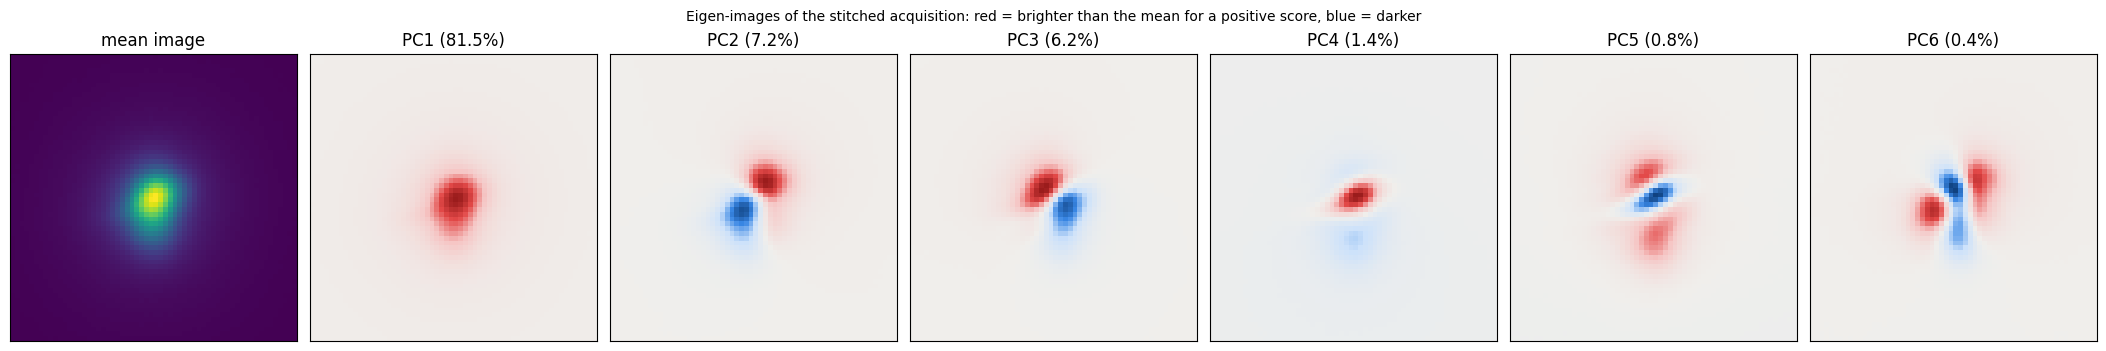

In [5]:
# eigen-images, zoomed on the beam: ±30 binned pixels (±1.3 mm) around the peak of the mean image
cy, cx = np.unravel_index(mean_image.argmax(), mean_image.shape)
zoom = (slice(max(cy - 30, 0), cy + 30), slice(max(cx - 30, 0), cx + 30))

fig, axes = plt.subplots(1, N_PCA + 1, figsize=(3 * (N_PCA + 1), 3.4), constrained_layout=True)
axes[0].imshow(mean_image[zoom], cmap="viridis")
axes[0].set_title("mean image")
for k, ax in enumerate(axes[1:]):
    lim = np.abs(eigen_images[k]).max()
    ax.imshow(eigen_images[k][zoom], cmap=DIVERGING, vmin=-lim, vmax=lim)
    ax.set_title(f"PC{k + 1} ({explained[k]:.1%})")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Eigen-images of the stitched acquisition: red = brighter than the mean for a positive score, blue = darker", fontsize=10)
fig.savefig(OUT / "pca_eigen_images.png", dpi=130, bbox_inches="tight")
plt.show()

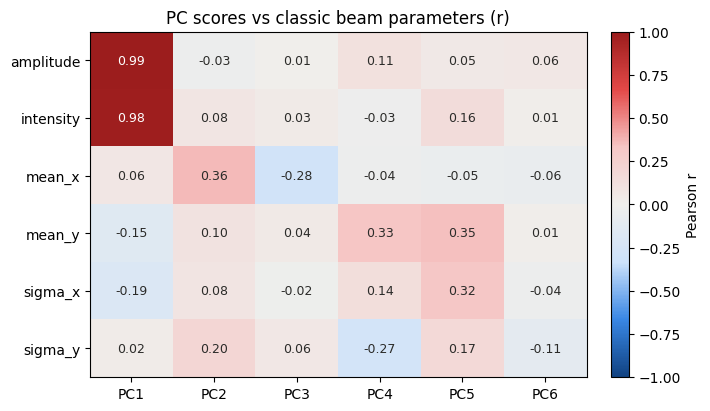

In [6]:
# what each PC looks like in the classic parameters (all stitched, non-frozen shots) — helps to name them
ok = ~btv_frozen & raw["BTV_amplitude"].notna().to_numpy()
pcs = [f"PC{k + 1}" for k in range(N_PCA)]
classic = raw.loc[ok, [f"BTV_{c}" for c in BTV_COLS]].set_axis(BTV_COLS, axis=1)
naming = pd.DataFrame({pc: classic.corrwith(raw.loc[ok, pc]) for pc in pcs})   # pairwise: skips NaN sigmas

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
im = ax.imshow(naming, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
for (i, j), r in np.ndenumerate(naming.to_numpy()):
    ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(r) > 0.6 else INK)
ax.set_xticks(range(N_PCA), pcs)
ax.set_yticks(range(len(BTV_COLS)), BTV_COLS)
ax.set_title("PC scores vs classic beam parameters (r)")
fig.colorbar(im, ax=ax, label="Pearson r")
fig.savefig(OUT / "pca_vs_classic.png", dpi=130, bbox_inches="tight")
plt.show()

## Align (group B one row later, within the segment) and clean

In [7]:
def detrend(df, segment, k=DETREND_K):
    """Remove slow drift: subtract a k-shot centred rolling mean, per segment."""
    trend = df.groupby(segment).transform(lambda s: s.rolling(k, center=True, min_periods=1).mean())
    return df - trend


data = raw.copy()
data[GROUP_B] = raw[GROUP_B].groupby(seg).shift(-1)                   # row i now holds group B from row i + 1
laser_frozen_aligned = pd.Series(laser_frozen).groupby(seg).shift(-1).eq(True).to_numpy()
complete = data[GROUP_B].notna().any(axis=1).to_numpy()               # last row of each segment has no partner
keep = ~laser_frozen_aligned & ~btv_frozen & complete
print(f"kept {keep.sum()} / {len(keep)} shots (dropped {laser_frozen_aligned.sum()} frozen laser, "
      f"{btv_frozen.sum()} frozen camera, {(~complete).sum()} lost to the shift)")

data, seg_kept = data[keep], seg[keep]
segments["kept"] = pd.Series(seg_kept).value_counts().reindex(segments.index, fill_value=0)
segments

kept 53091 / 63327 shots (dropped 10076 frozen laser, 177 frozen camera, 8 lost to the shift)


,run,first_chunk,last_chunk,shots,kept
segment,,,,,
0,acquisition_2026-10-07_21-43-26,11,71,6027,4637
1,acquisition_2026-10-08_00-08-19,0,193,19400,16658
2,acquisition_2026-10-08_15-42-27,0,1,200,154
3,acquisition_2026-10-08_15-42-27,4,74,7100,5427
4,acquisition_2026-10-08_15-42-27,76,120,4500,3855
5,acquisition_2026-10-08_21-11-47,0,199,20000,17443
6,acquisition_2026-10-09_07-46-07,0,40,4100,3137
7,acquisition_2026-10-09_07-46-07,87,106,2000,1780


## Correlation plot for every segment

Lower triangle only. Left: **overall** (includes slow drift within the segment). Right: **shot-to-shot**
(51-shot rolling mean removed). |r| below ~2/√N is at the noise level (N = shots in the segment, in the title).
Lines separate the groups: charge · laser · waveforms · magnets · screen (classic) · screen (PCA).

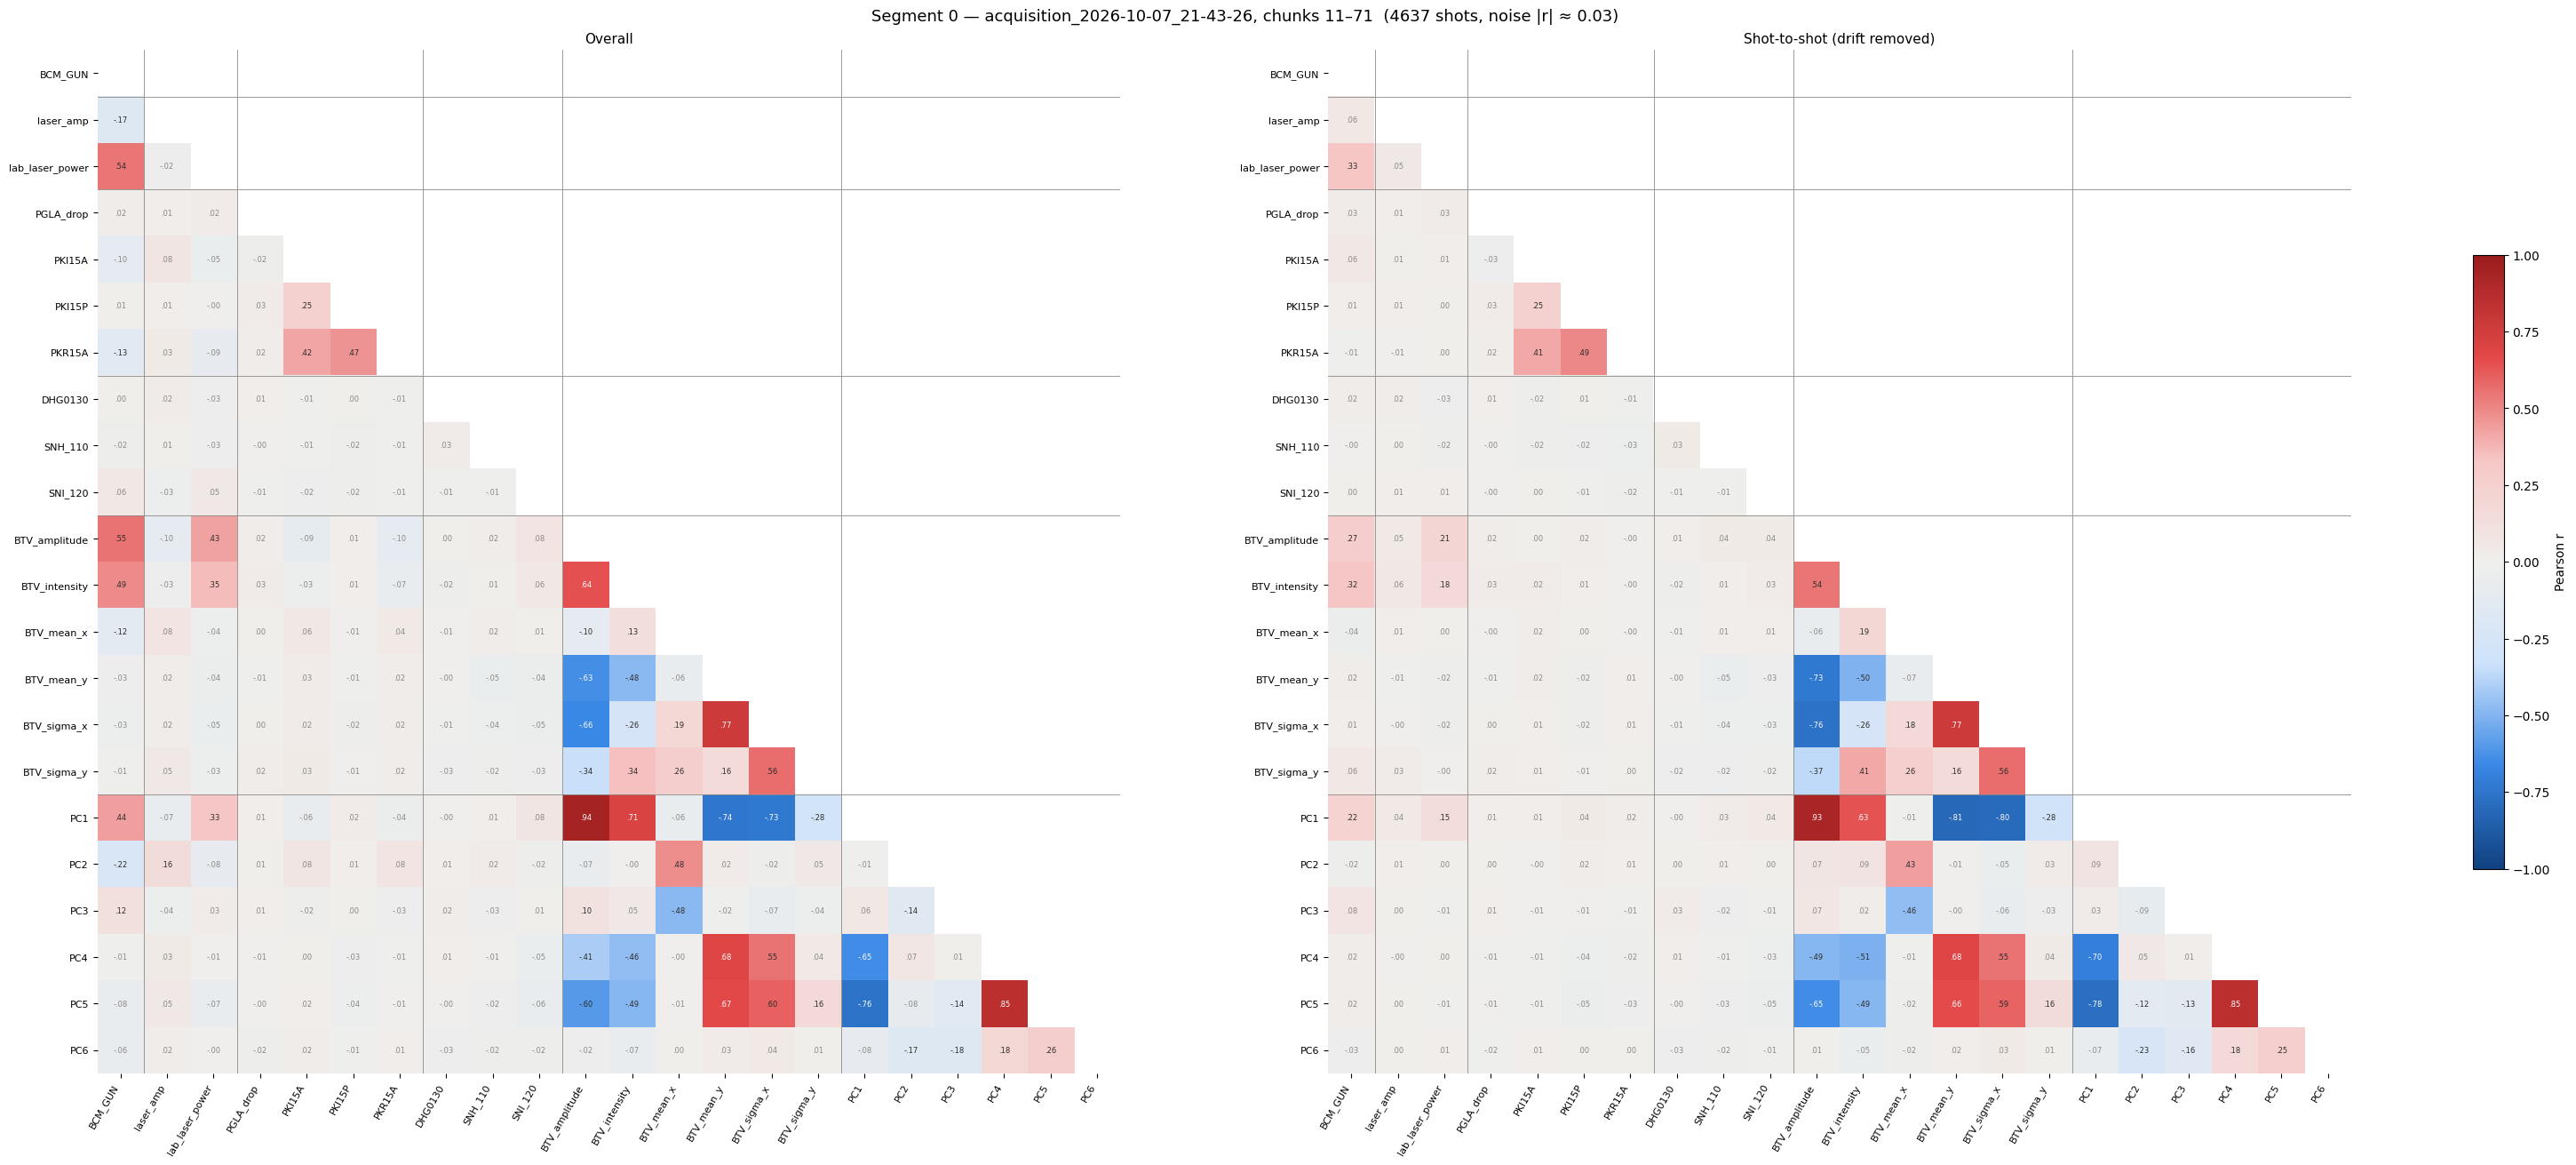

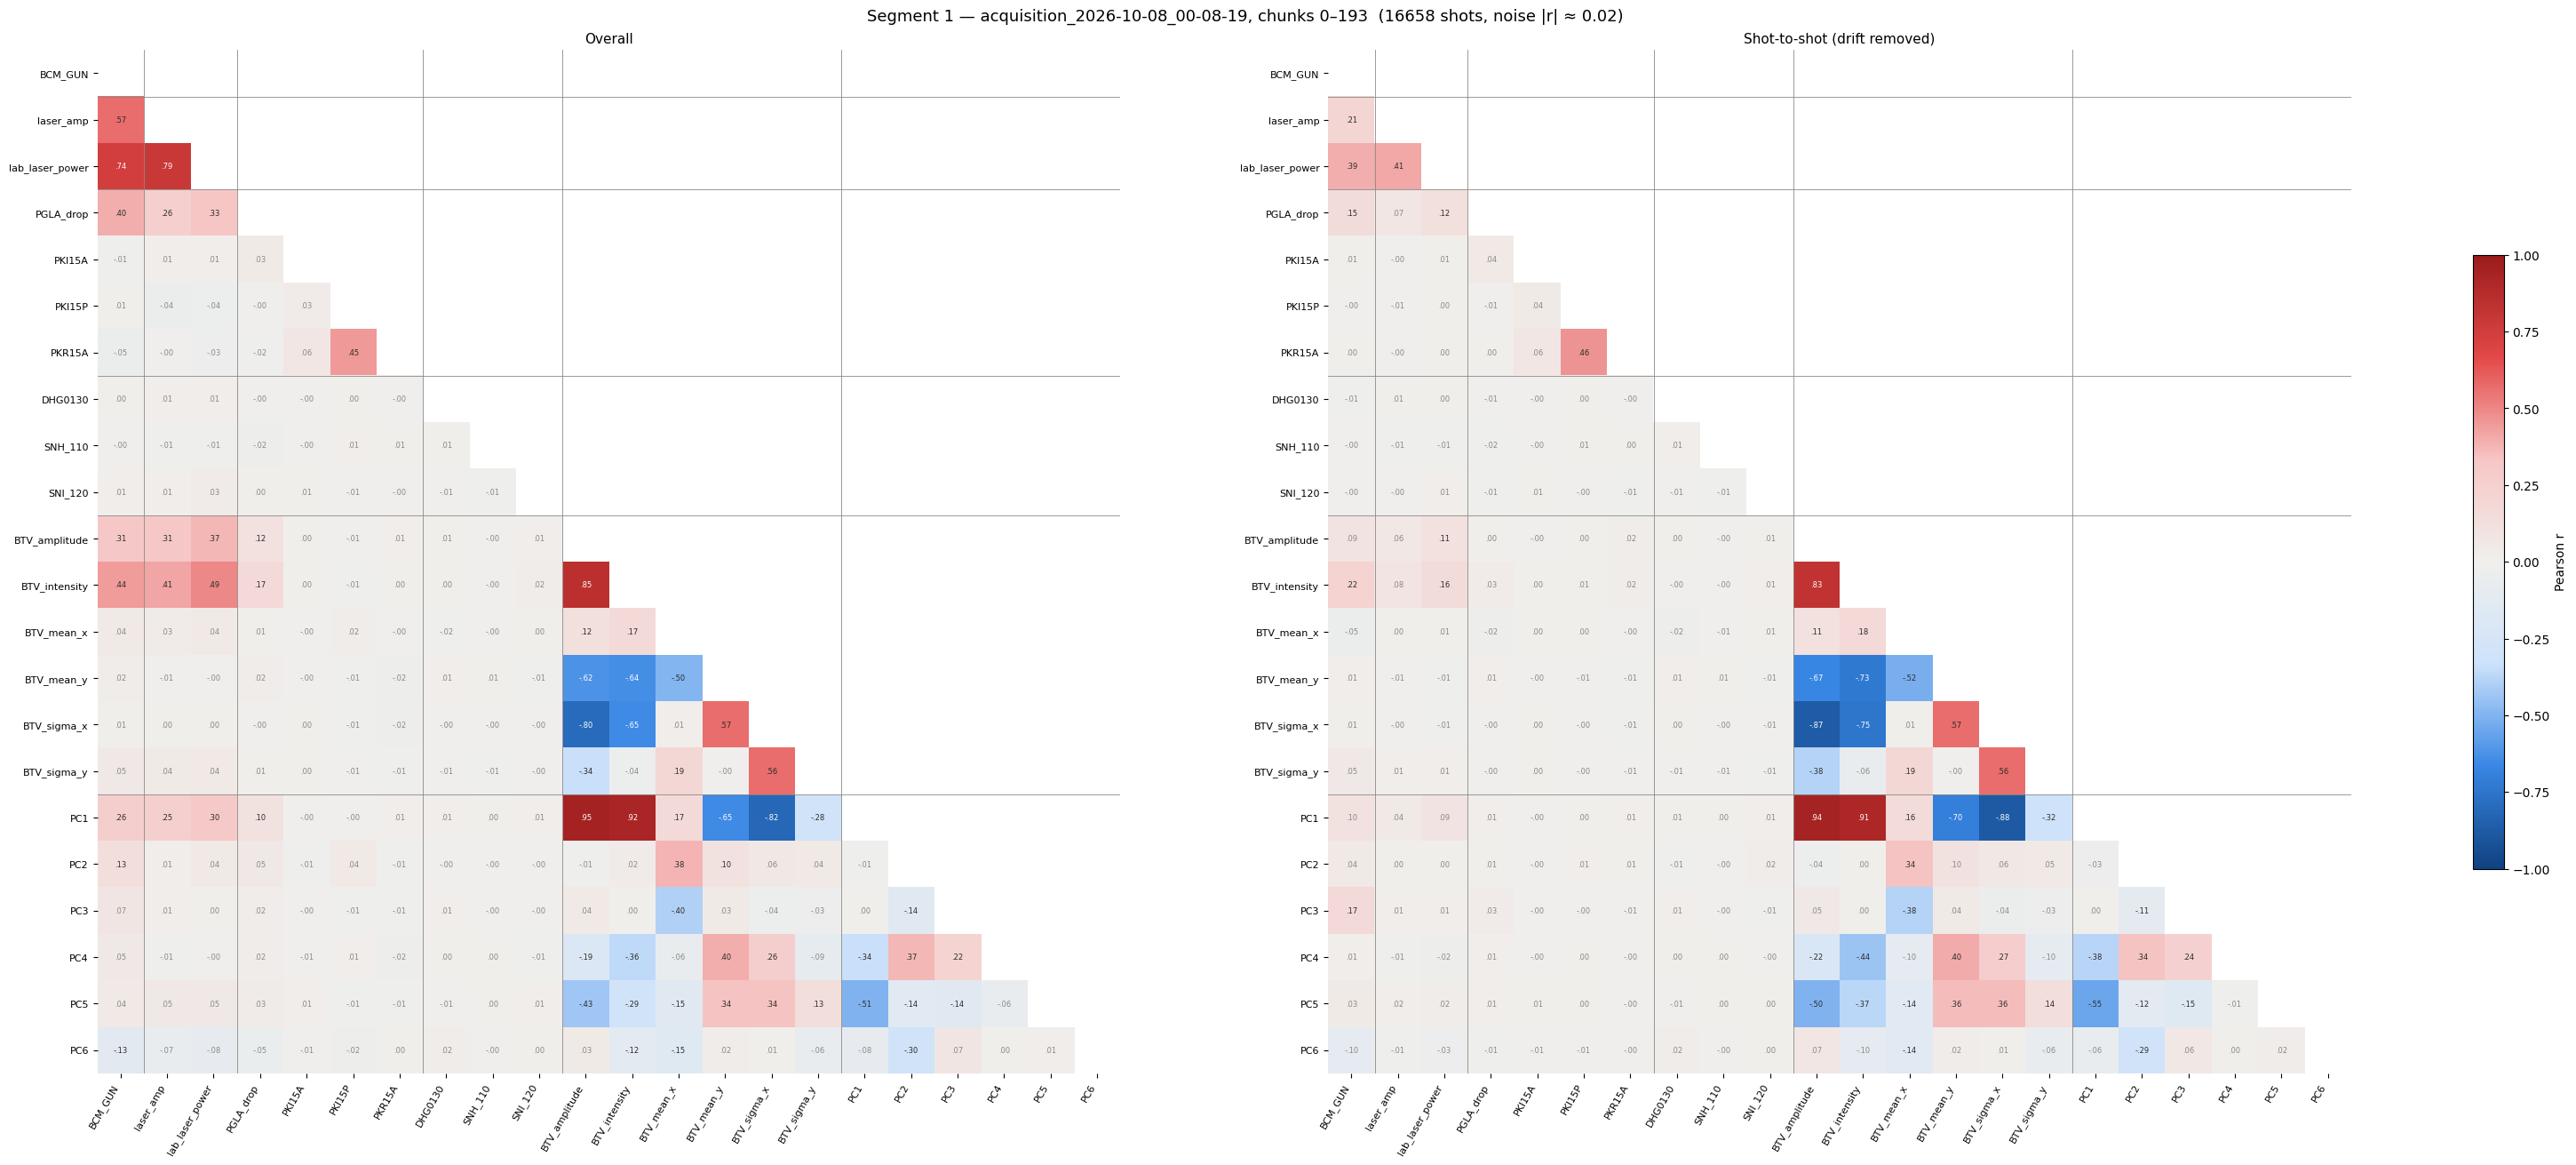

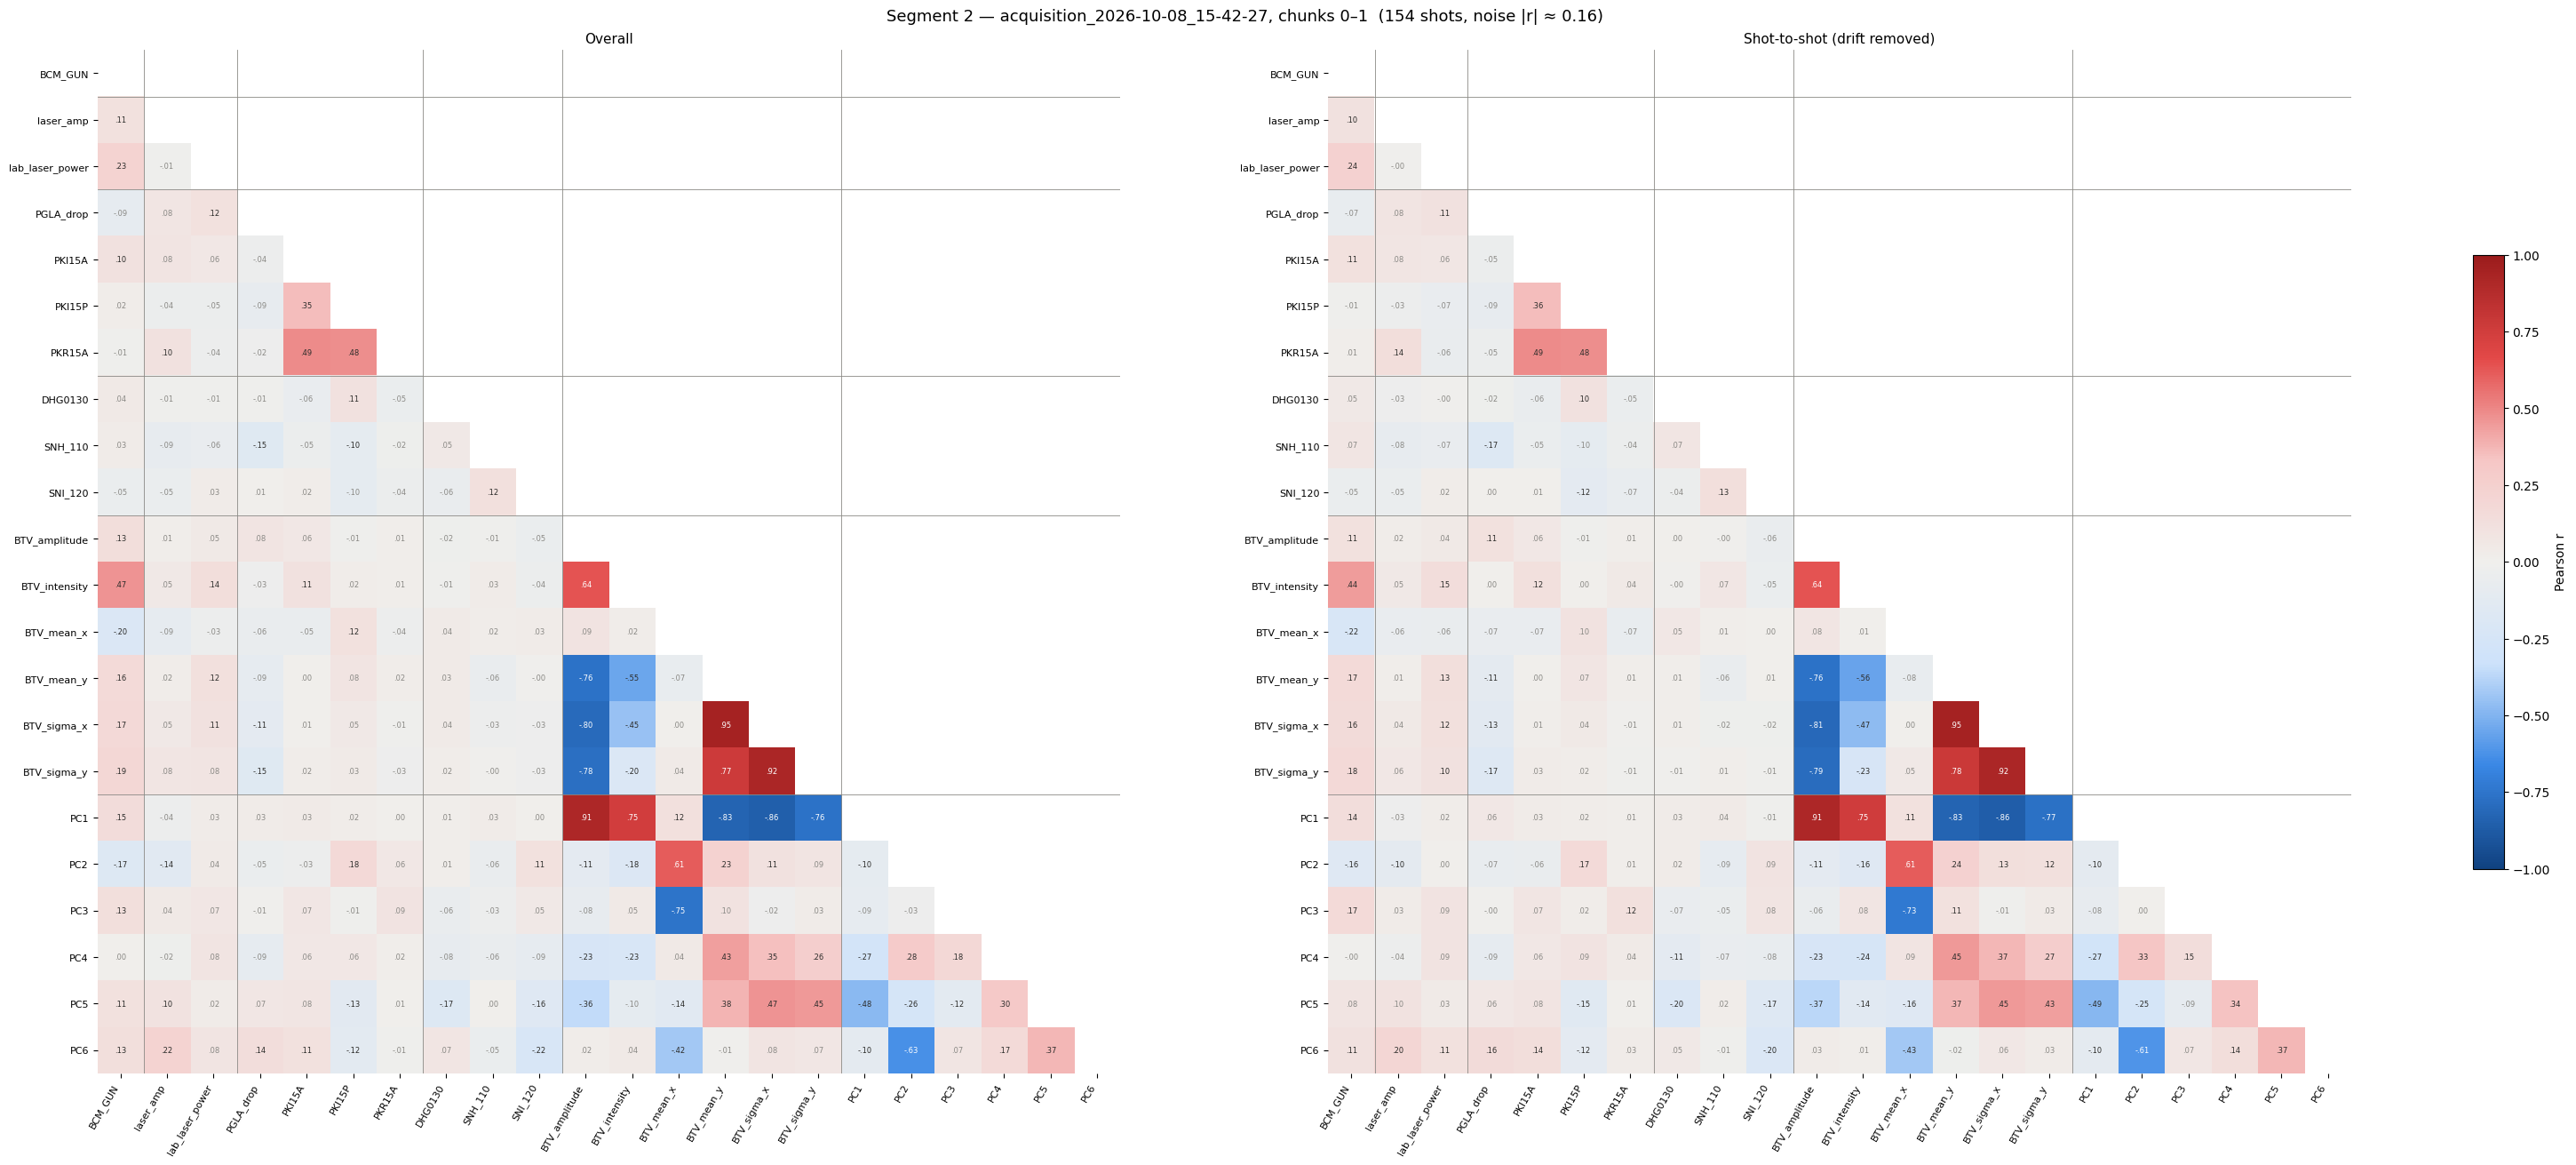

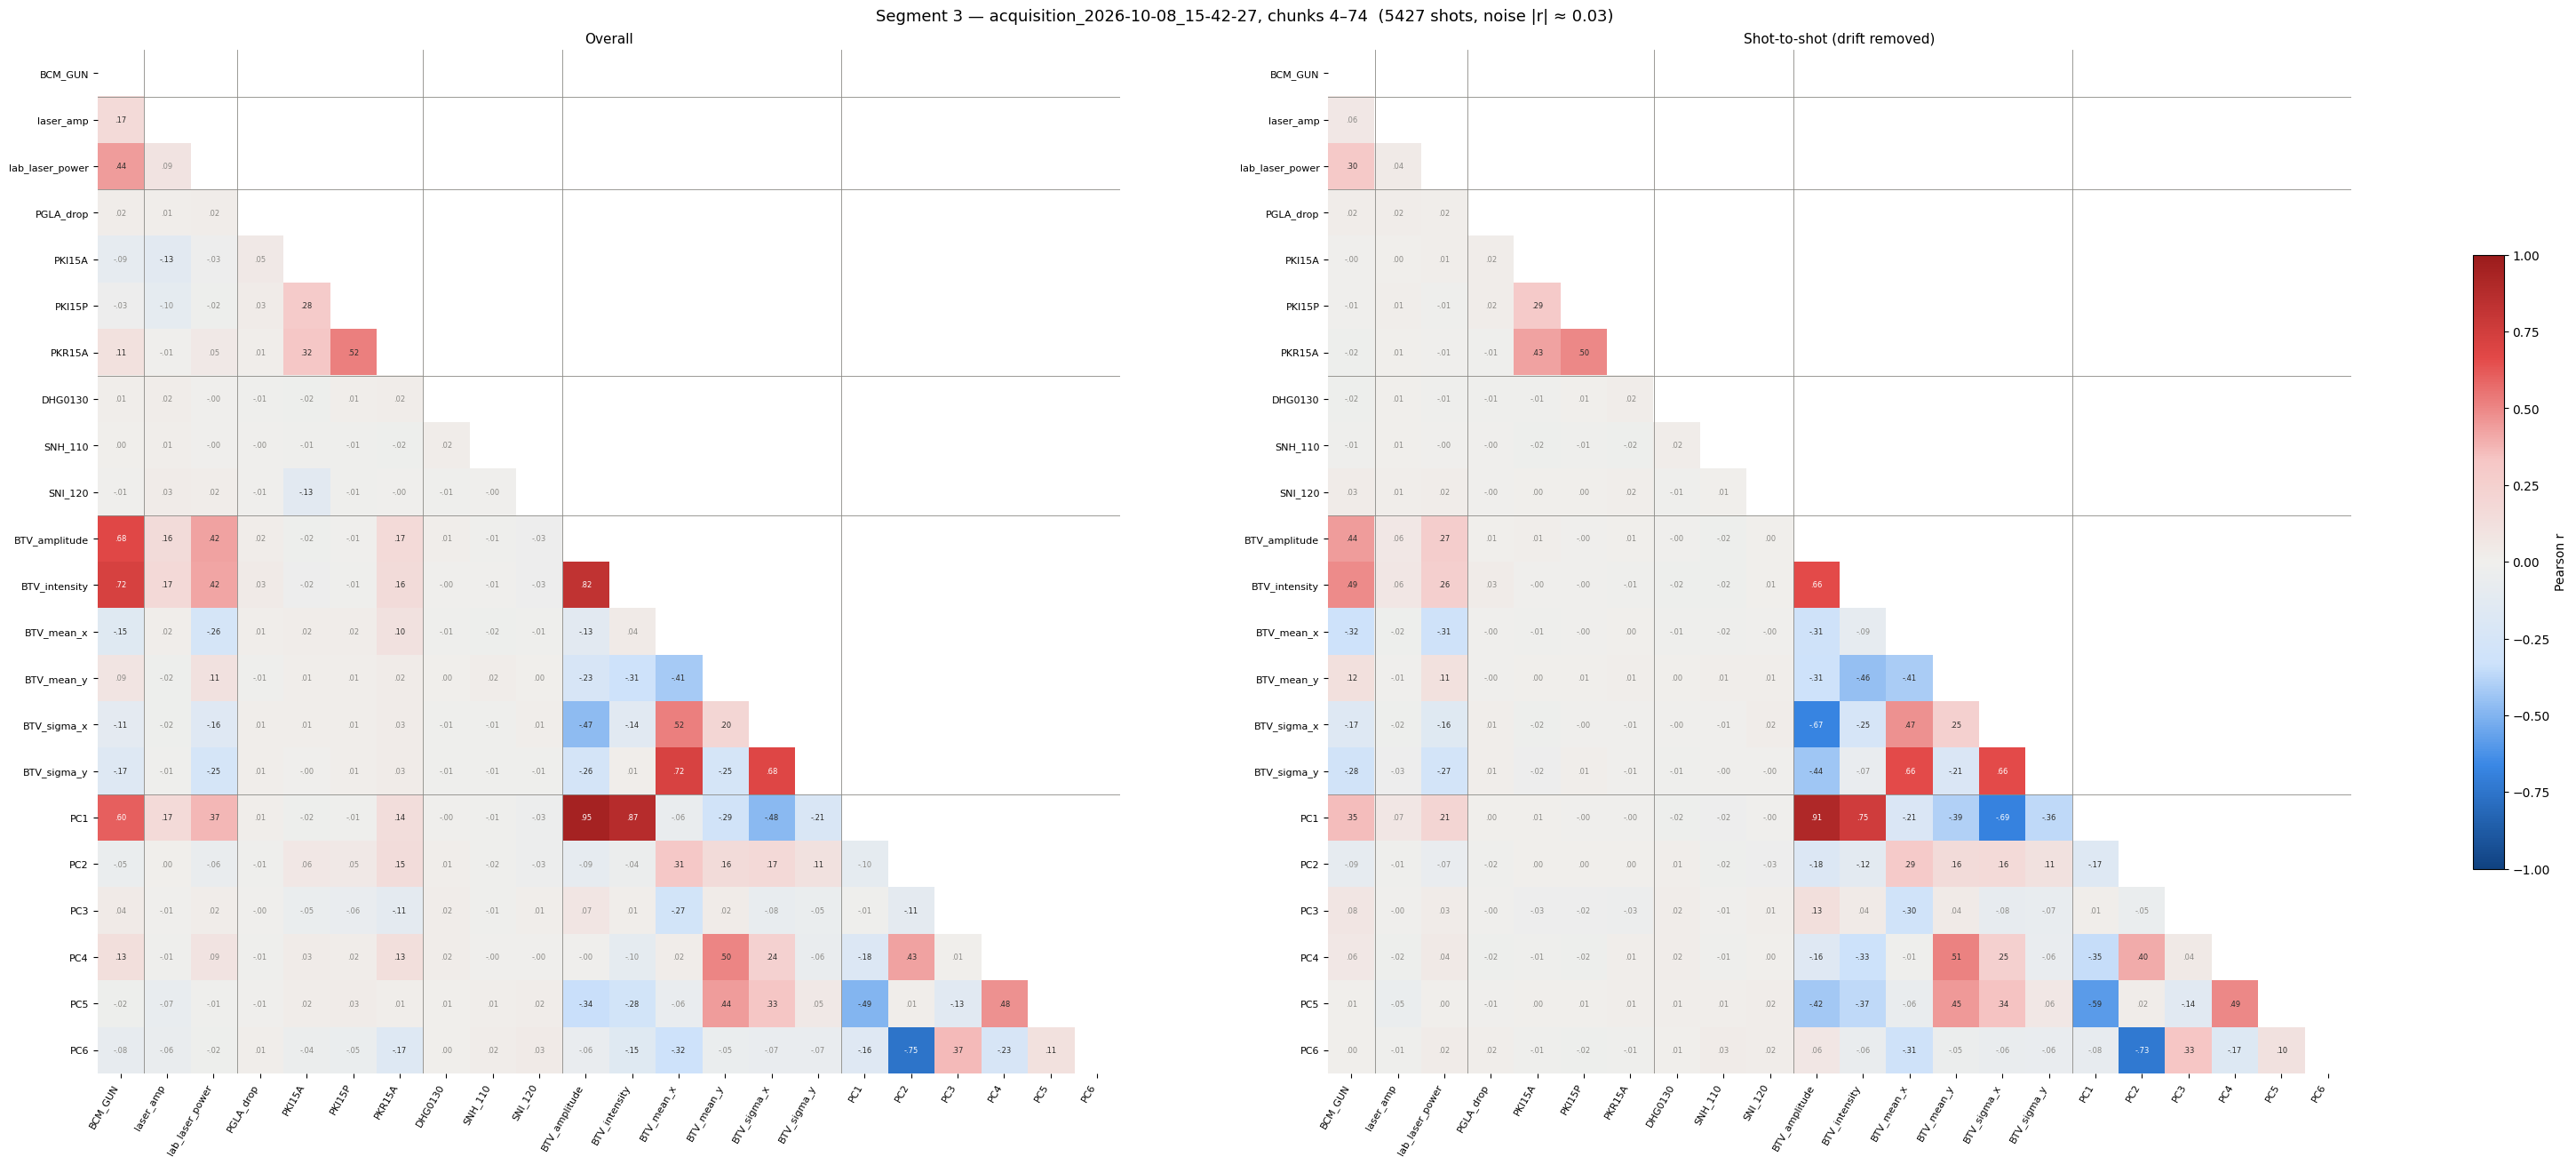

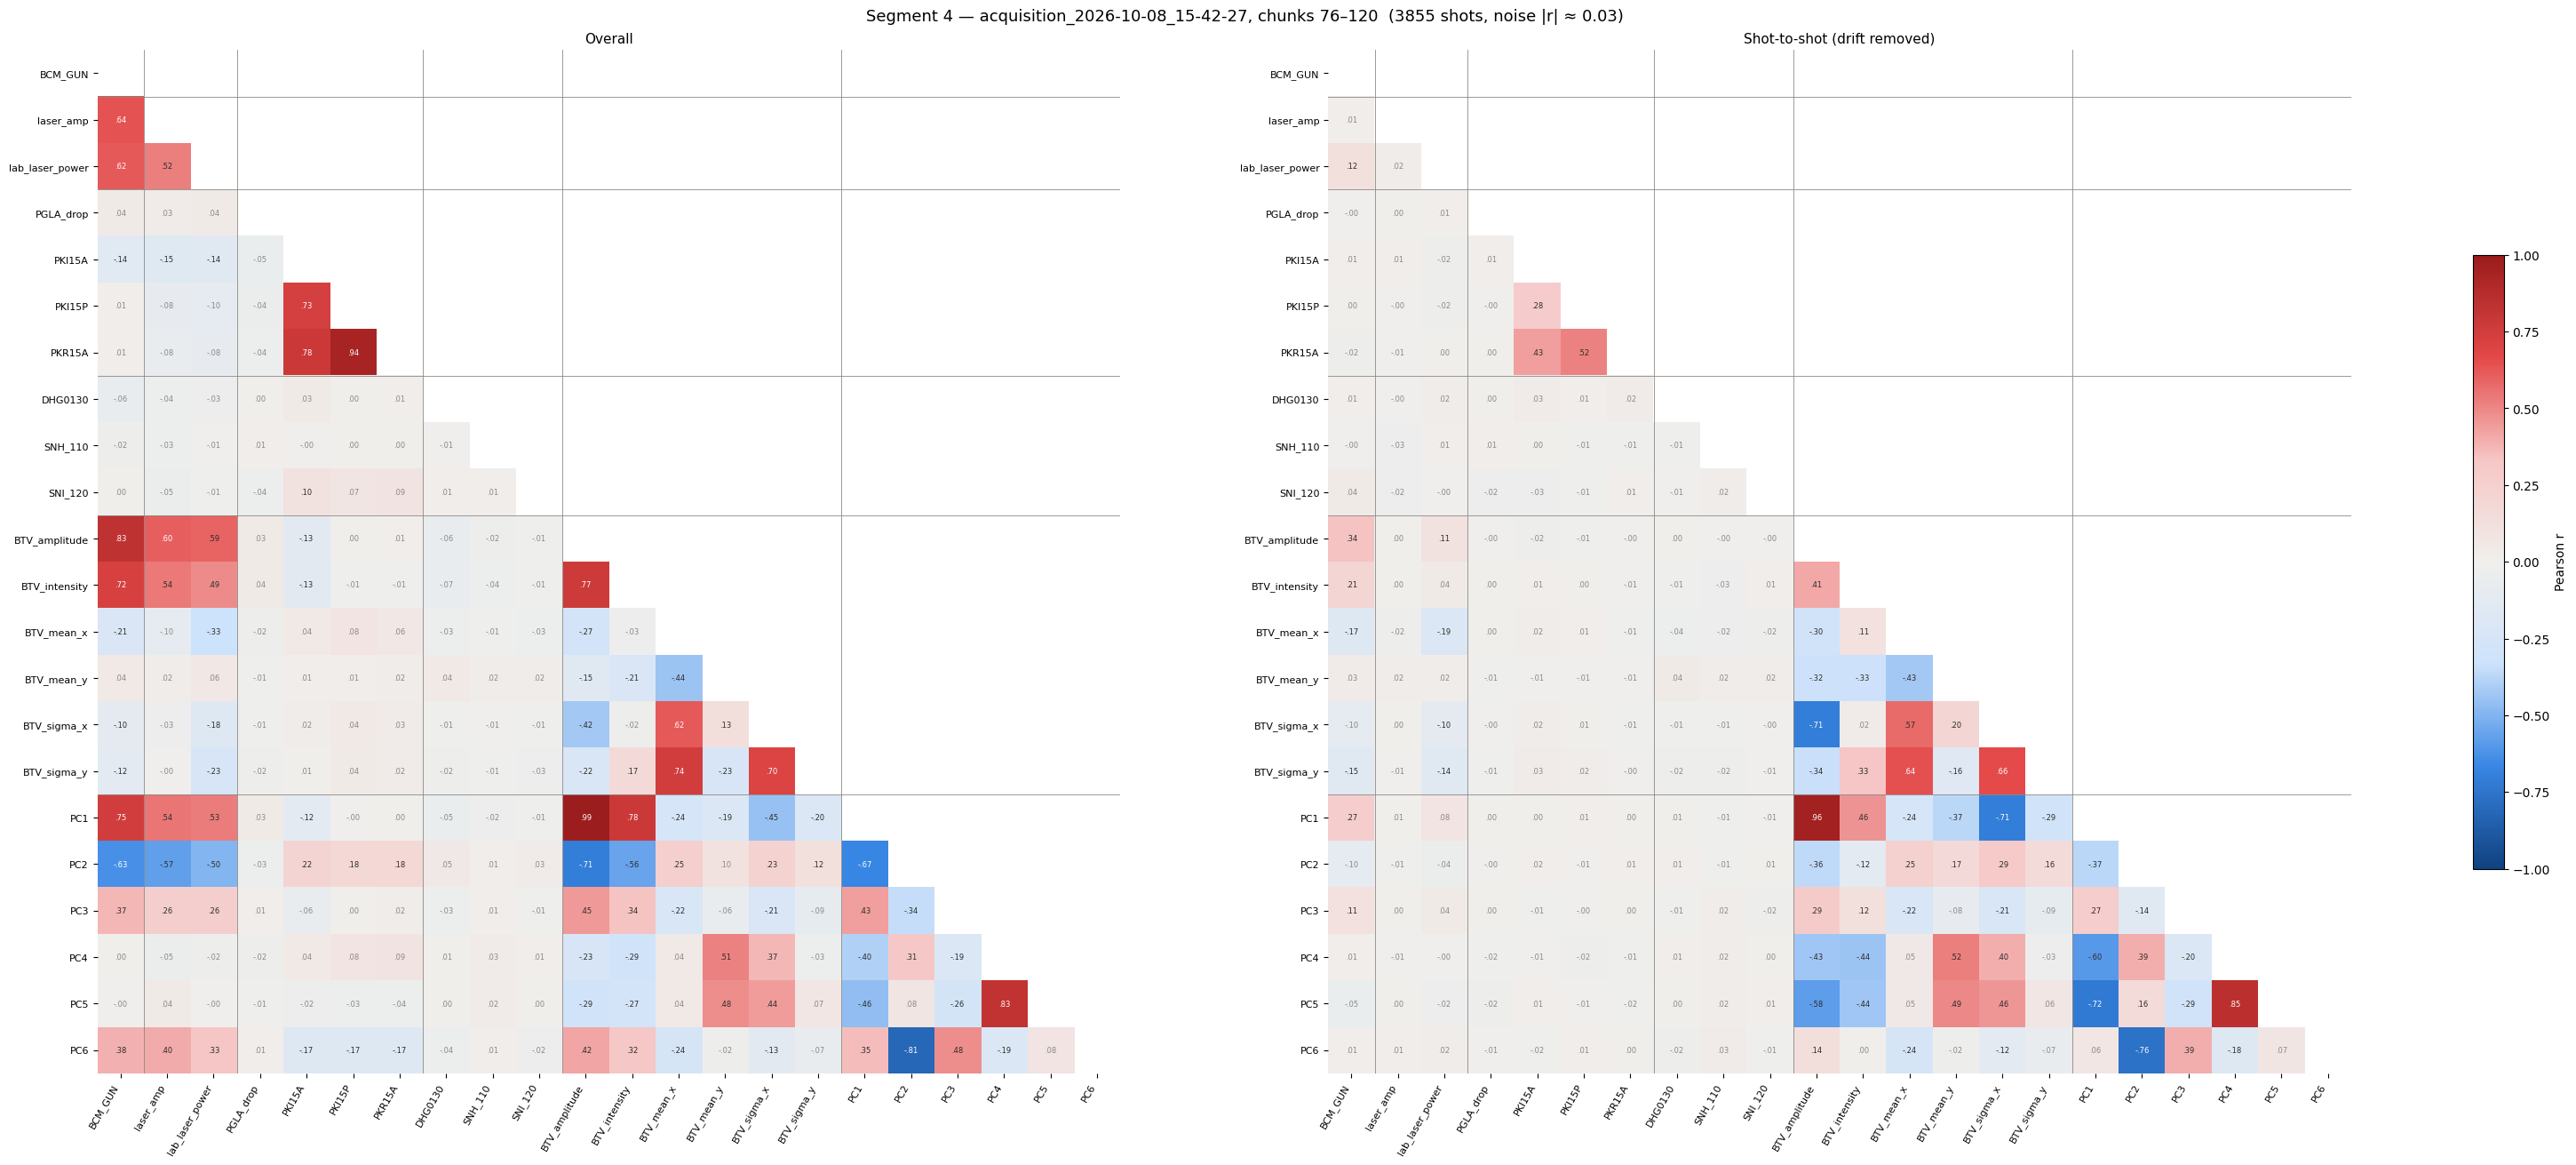

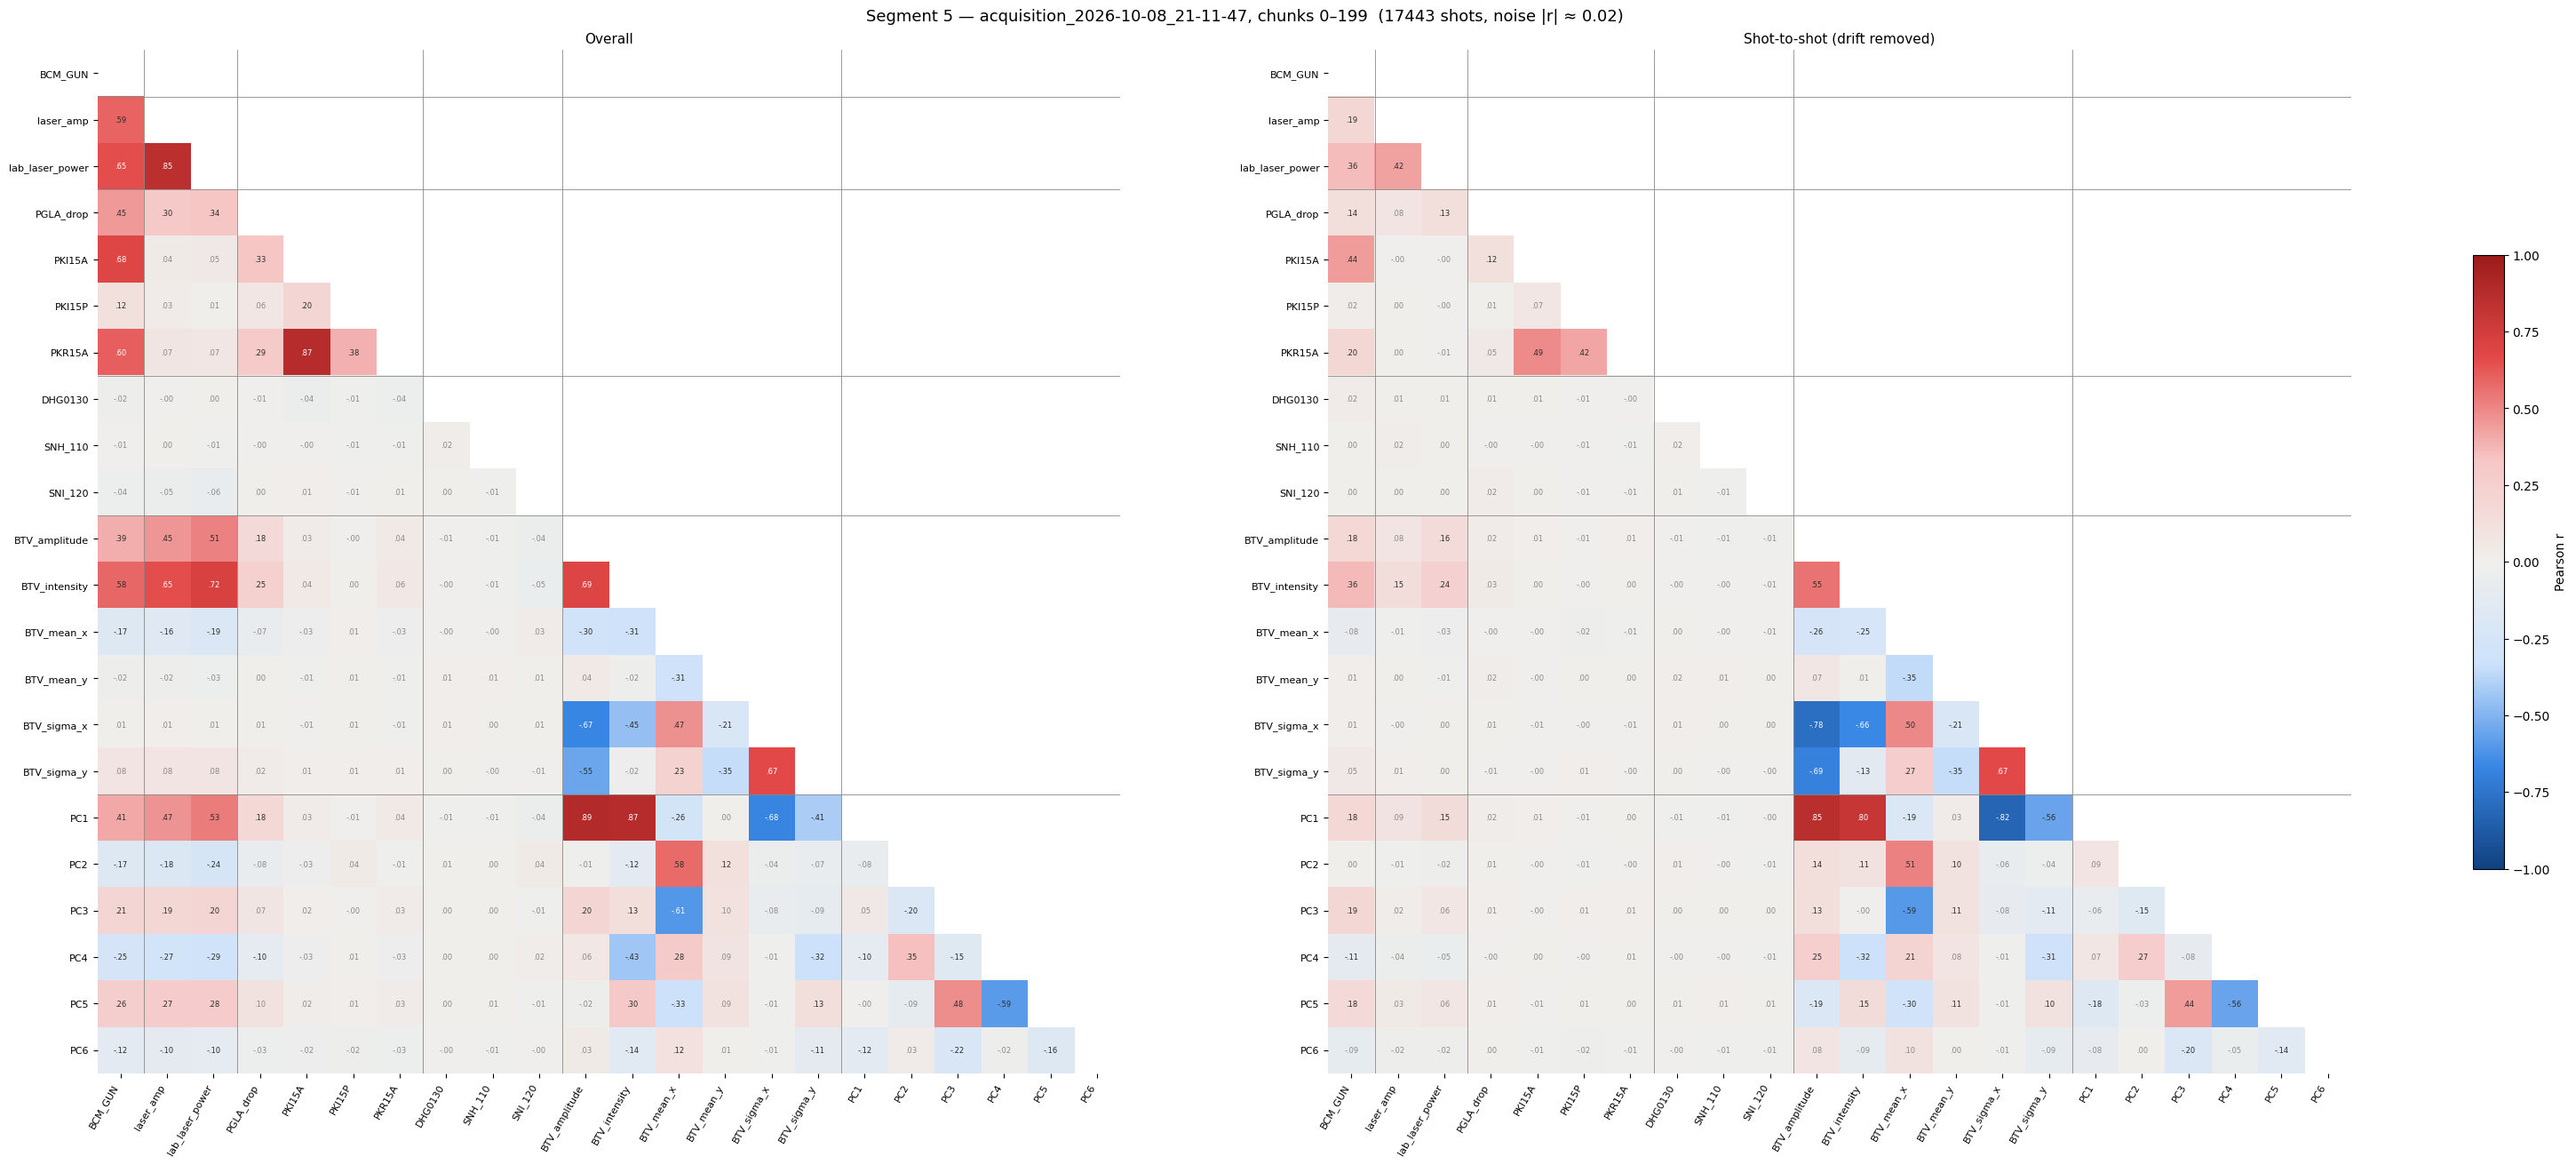

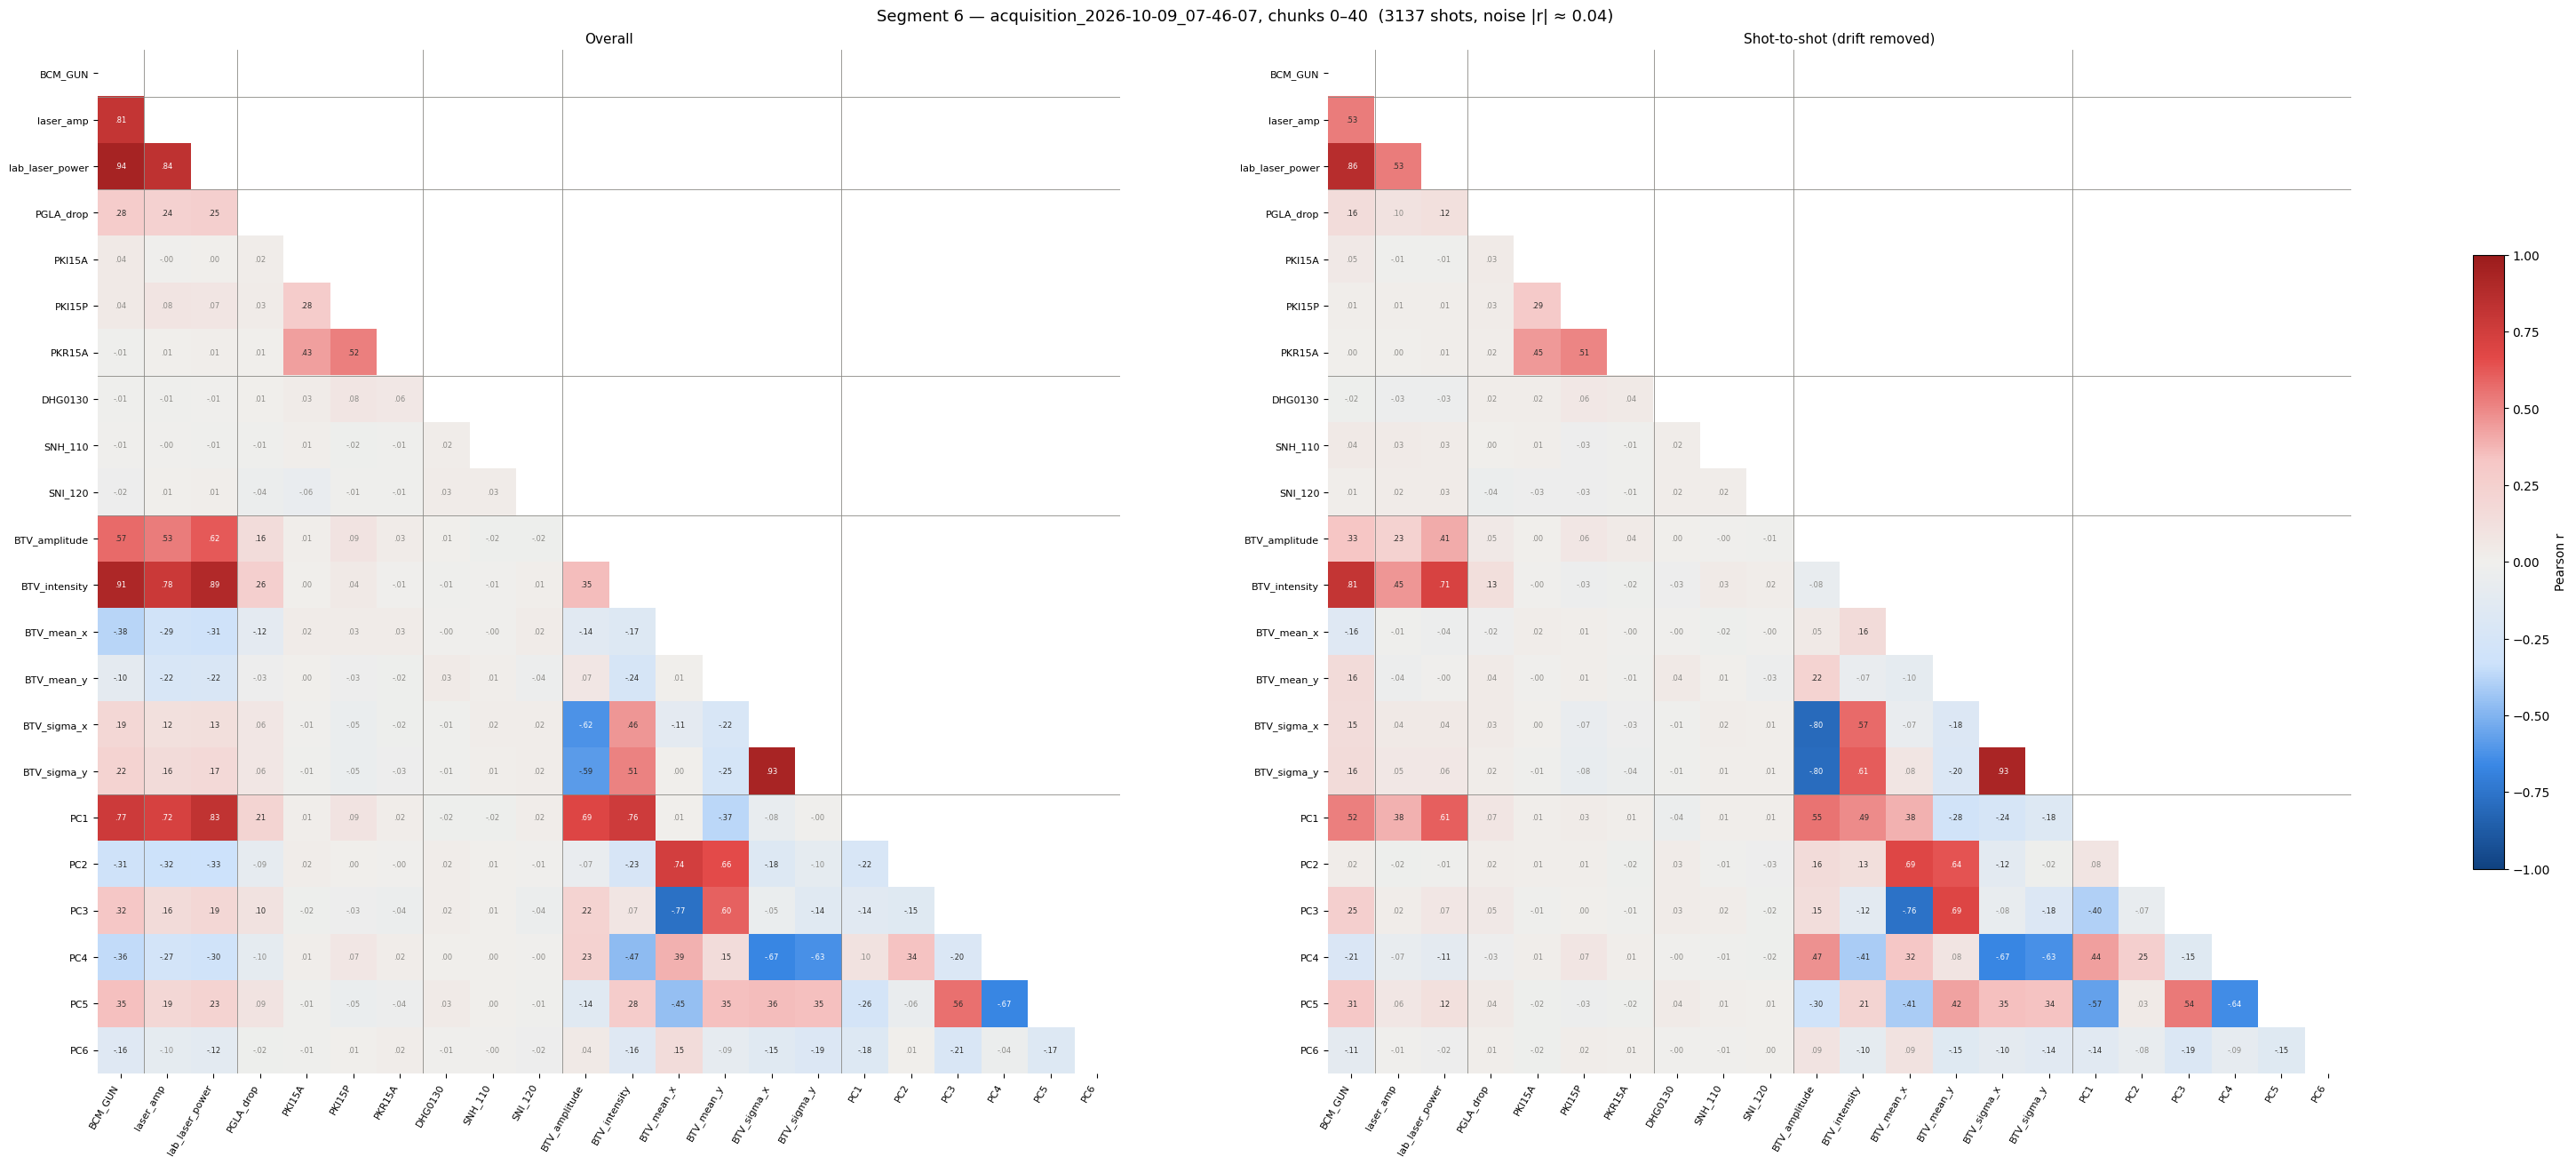

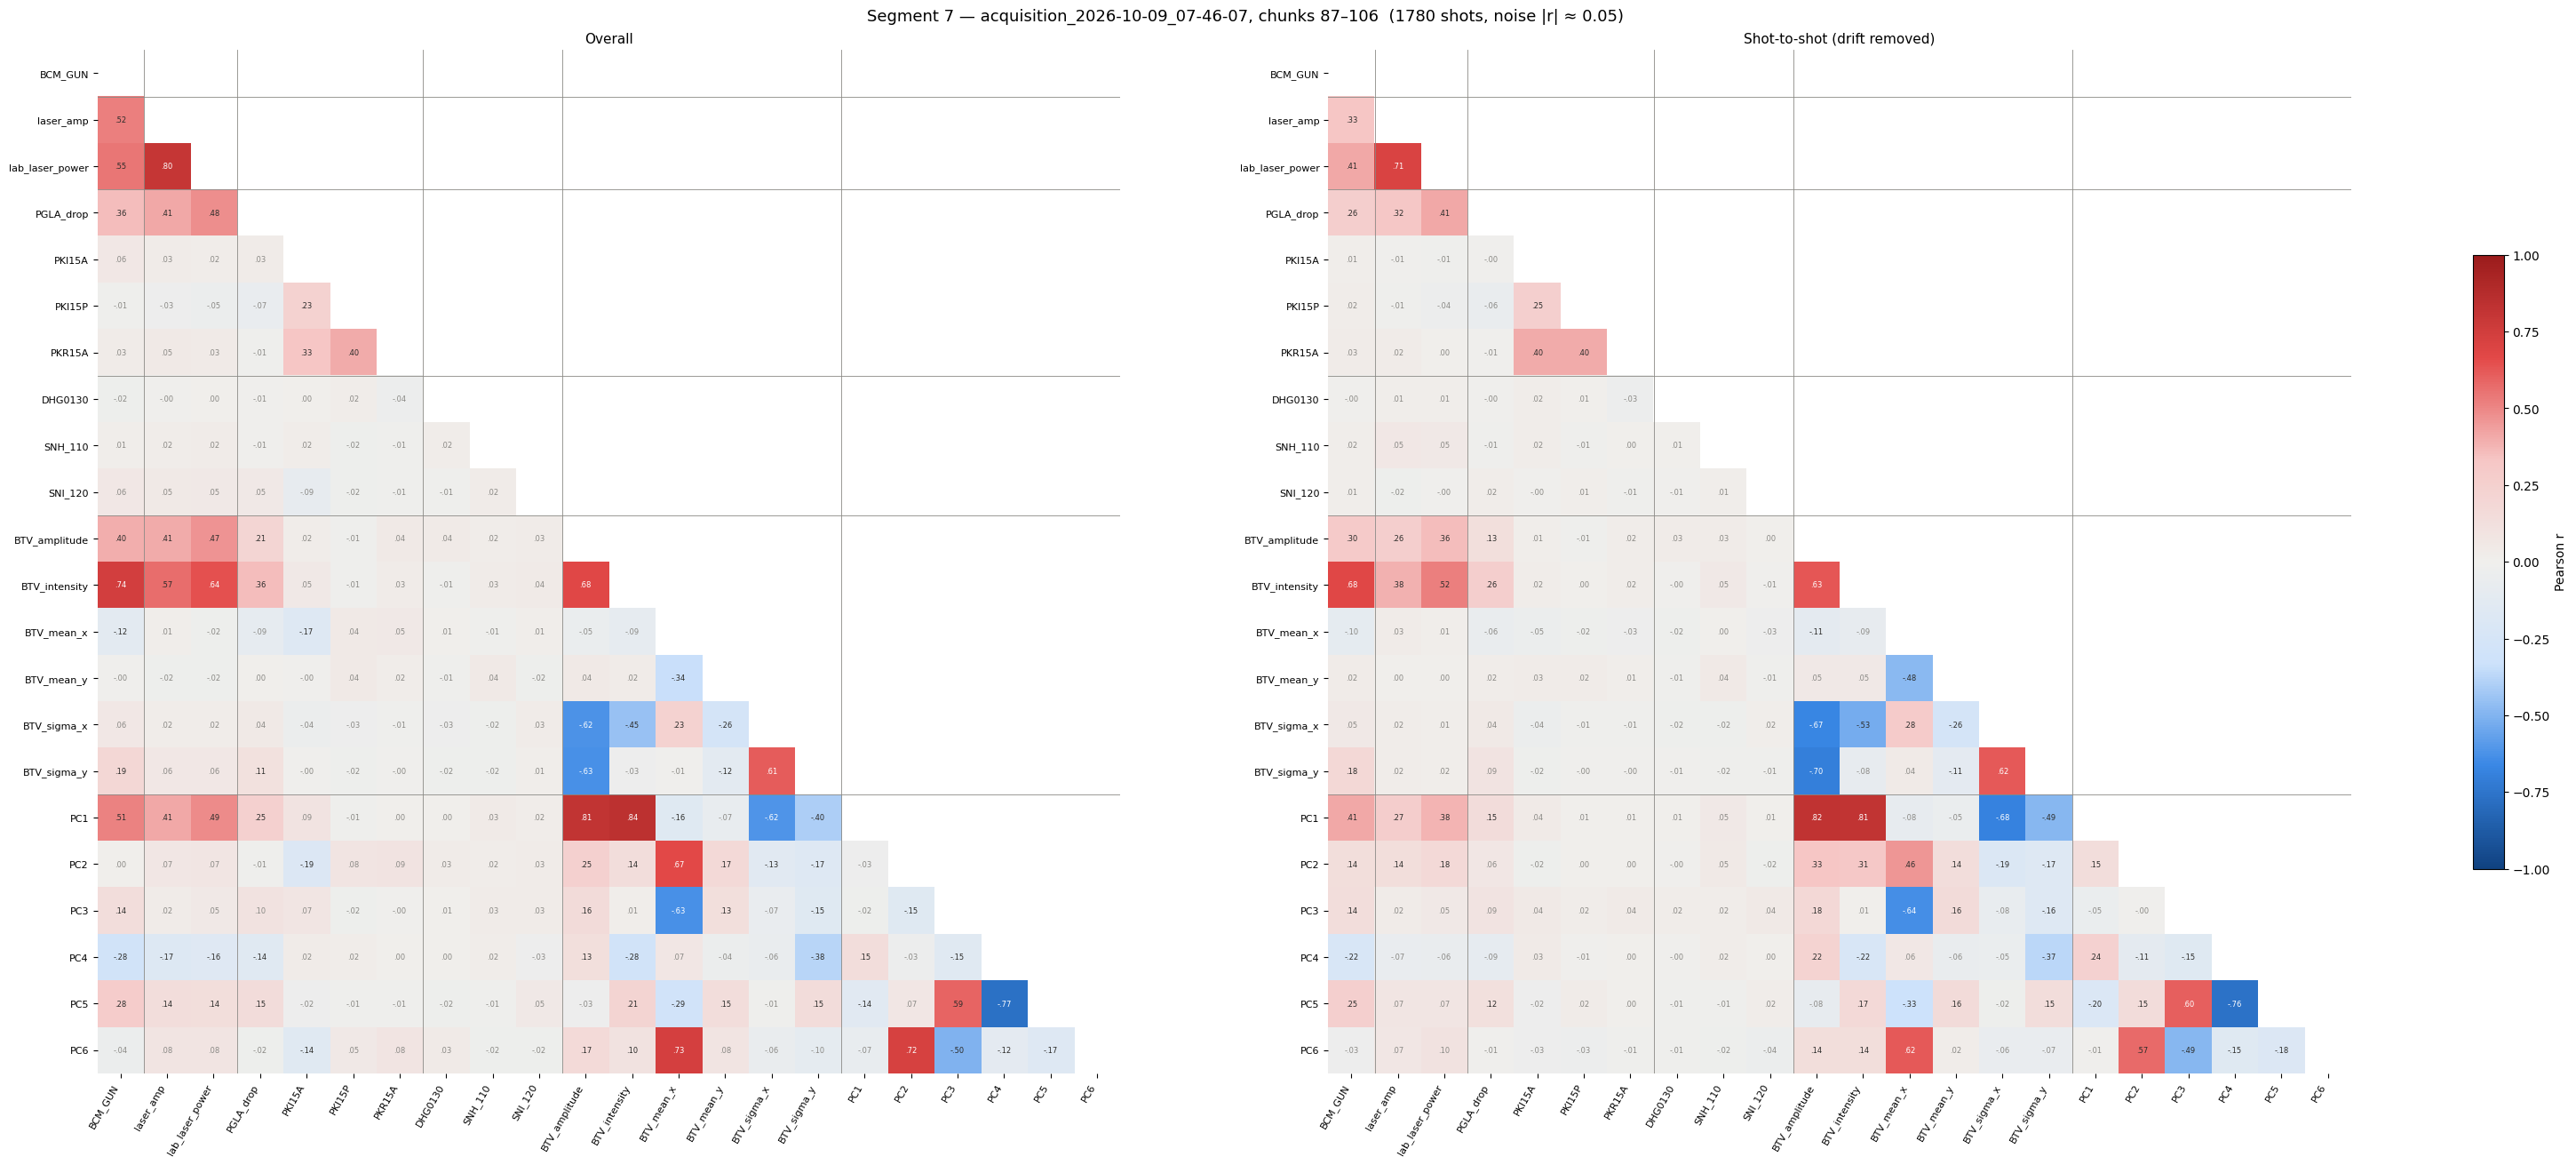

In [8]:
names = data.columns
lower = np.tril(np.ones((len(names), len(names)), dtype=bool), k=-1)
edges = [names.get_loc(c) - 0.5 for c in GROUP_EDGES if c in names]


def corr_panel(ax, m, title):
    shown = np.where(lower, m.to_numpy(), np.nan)
    im = ax.imshow(shown, cmap=DIVERGING, vmin=-1, vmax=1)
    for (i, j), r in np.ndenumerate(shown):
        if not np.isnan(r):
            ax.text(j, i, f"{r:.2f}".replace("0.", "."), ha="center", va="center", fontsize=6,
                    color="white" if abs(r) > 0.6 else (INK if abs(r) >= 0.1 else MUTED))
    for e in edges:
        ax.axhline(e, color=MUTED, lw=0.6)
        ax.axvline(e, color=MUTED, lw=0.6)
    ax.set_xticks(range(len(names)), names, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(names)), names, fontsize=8)
    ax.set_title(title, fontsize=11)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return im


matrices, rows = {}, []
for k, info in segments.iterrows():
    m = seg_kept == k
    d = data[m]
    if len(d) < 2 * DETREND_K:
        print(f"segment {k}: only {len(d)} shots, skipped")
        continue
    mats = {"Overall": d.corr(), "Shot-to-shot (drift removed)": detrend(d, seg_kept[m]).corr()}
    matrices[k] = mats

    fig, axes = plt.subplots(1, 2, figsize=(30, 13), constrained_layout=True)
    for ax, (title, mat) in zip(axes, mats.items()):
        im = corr_panel(ax, mat, title)
    fig.colorbar(im, ax=axes, shrink=0.6, label="Pearson r")
    fig.suptitle(f"Segment {k} — {info['run']}, chunks {info['first_chunk']}–{info['last_chunk']}  "
                 f"({len(d)} shots, noise |r| ≈ {2 / np.sqrt(len(d)):.2f})", fontsize=13)
    fig.savefig(OUT / f"segment_{k:02d}.png", dpi=130, bbox_inches="tight")
    plt.show()

    for kind, mat in mats.items():
        long = mat.where(lower).stack().rename("r").reset_index()
        rows.append(long.rename(columns={"level_0": "a", "level_1": "b"}).assign(segment=k, kind=kind))

pd.concat(rows)[["segment", "kind", "a", "b", "r"]].to_csv(OUT / "segment_correlations.csv", index=False)

## Comparison of the segments

Shot-to-shot r of every quantity with `BCM_GUN`, one column per segment — what holds across segments is
more trustworthy than what shows up in one.

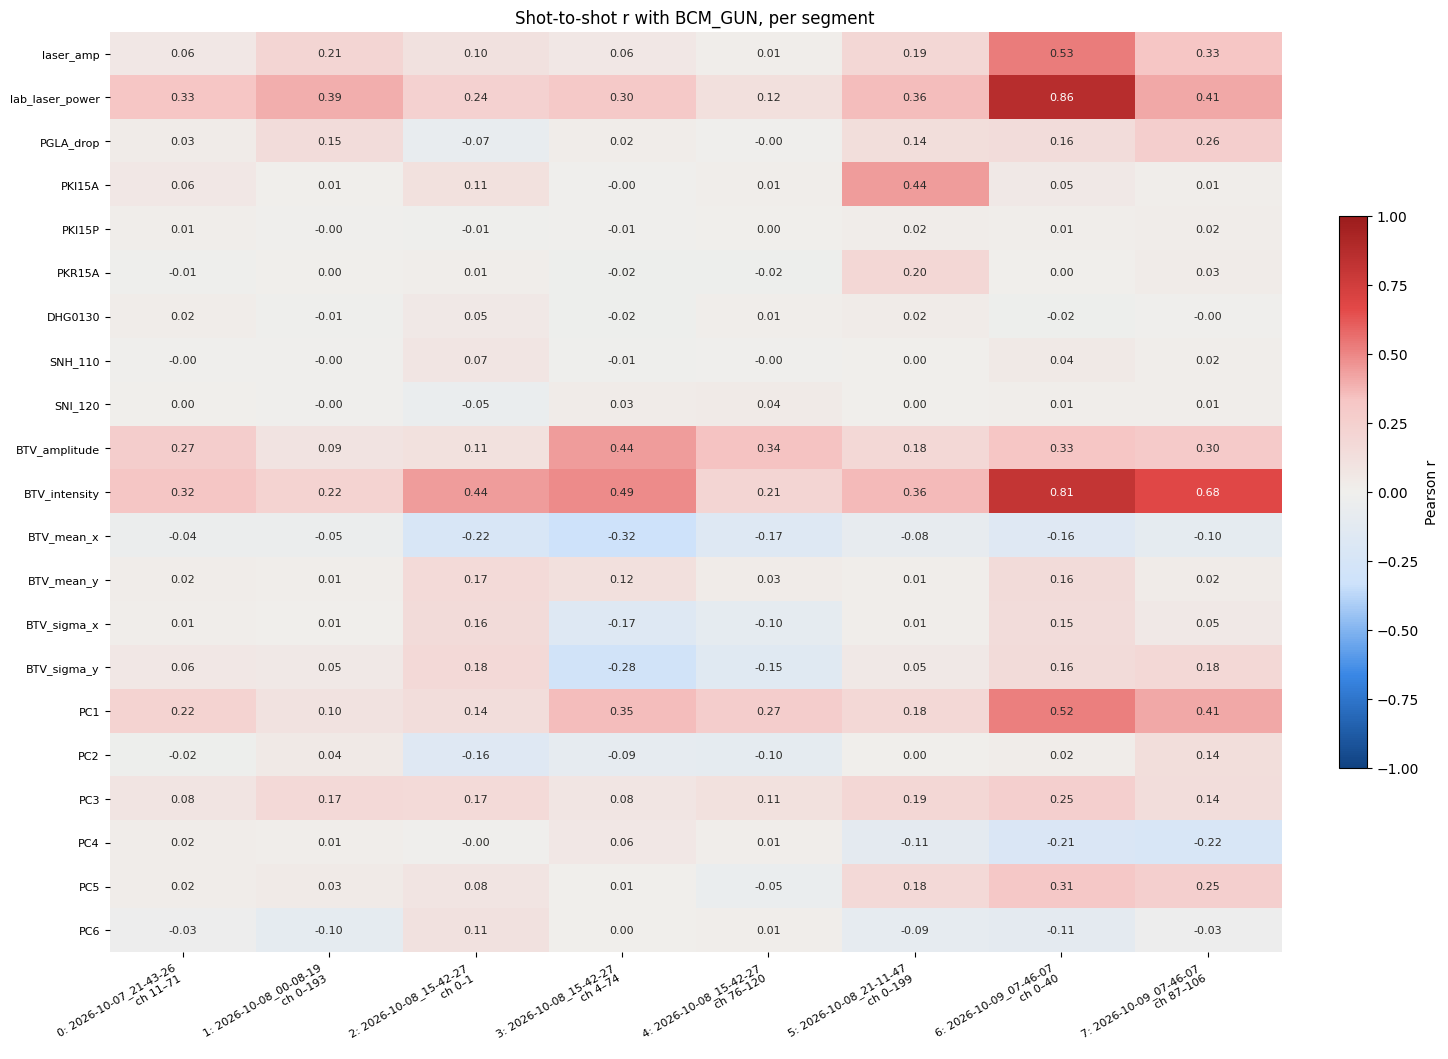

,0,1,2,3,4,5,6,7
laser_amp,0.06,0.21,0.10,0.06,0.01,0.19,0.53,0.33
lab_laser_power,0.33,0.39,0.24,0.30,0.12,0.36,0.86,0.41
PGLA_drop,0.03,0.15,-0.07,0.02,-0.00,0.14,0.16,0.26
PKI15A,0.06,0.01,0.11,-0.00,0.01,0.44,0.05,0.01
PKI15P,0.01,-0.00,-0.01,-0.01,0.00,0.02,0.01,0.02
PKR15A,-0.01,0.00,0.01,-0.02,-0.02,0.20,0.00,0.03
DHG0130,0.02,-0.01,0.05,-0.02,0.01,0.02,-0.02,-0.00
SNH_110,-0.00,-0.00,0.07,-0.01,-0.00,0.00,0.04,0.02
SNI_120,0.00,-0.00,-0.05,0.03,0.04,0.00,0.01,0.01
BTV_amplitude,0.27,0.09,0.11,0.44,0.34,0.18,0.33,0.30


In [9]:
KIND = "Shot-to-shot (drift removed)"
vs_bcm = pd.DataFrame({k: mats[KIND]["BCM_GUN"].drop("BCM_GUN") for k, mats in matrices.items()})
labels = [f"{k}: {segments.loc[k, 'run'].removeprefix('acquisition_')}\nch {segments.loc[k, 'first_chunk']}–{segments.loc[k, 'last_chunk']}"
          for k in vs_bcm.columns]

fig, ax = plt.subplots(figsize=(1.3 * len(vs_bcm.columns) + 4, 0.38 * len(vs_bcm) + 2.5), constrained_layout=True)
im = ax.imshow(vs_bcm, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
for (i, j), r in np.ndenumerate(vs_bcm.to_numpy()):
    ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(r) > 0.6 else INK)
ax.set_xticks(range(vs_bcm.shape[1]), labels, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(vs_bcm)), vs_bcm.index, fontsize=8)
ax.set_title("Shot-to-shot r with BCM_GUN, per segment")
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.6, label="Pearson r")
fig.savefig(OUT / "segments_vs_bcm.png", dpi=130, bbox_inches="tight")
plt.show()

vs_bcm.to_csv(OUT / "segments_vs_bcm.csv")
vs_bcm.round(2)